# Unit Line Detection

**Question:** Given raw tracking data during a pass event, can the Ward agglomerative clustering
approach detect the defending team's unit lines consistently?

**Data:** FIFA WC 2022 — Brazil vs South Korea (Round of 16, match 10507)  
**Module under test:** `turf.efi.line`

> **Requires:** `data/pff/wc2022/` populated (see README). Run with `uv sync --group viz` for plots.

In [1]:
import pathlib

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from turf.efi.line import analyze_lines, fix_player_assignments, vote_line_count
from turf.efi.viz import animate_lines, make_pitch, plot_frame, plot_lines_frame

%matplotlib inline
matplotlib.rcParams['figure.facecolor'] = '#0d0d0d'

np.random.seed(42)

DATA_DIR = pathlib.Path('../../data/pff/wc2022')
RESULTS_DIR = pathlib.Path('results')
RESULTS_DIR.mkdir(exist_ok=True)

MATCH_ID = 10507
HOME_TEAM = 'Home'   # Brazil
AWAY_TEAM = 'Away'   # South Korea

## Load and merge tracking data

Home and away tracking are stored in separate CSVs (one team per file).  
Merging on `Period` + `Time [s]` produces a combined wide-format frame.

In [2]:
home_tr = pd.read_csv(DATA_DIR / f'home_tracking_{MATCH_ID}.csv')
away_tr = pd.read_csv(DATA_DIR / f'away_tracking_{MATCH_ID}.csv')

# Merge — keep ball columns from home side only
away_no_ball = away_tr.drop(columns=['ball_x', 'ball_y'])
tracking = home_tr.merge(away_no_ball, on=['Period', 'Time [s]'], how='inner')

events = pd.read_csv(DATA_DIR / f'event_data_{MATCH_ID}.csv')

print(f'Tracking frames: {len(tracking):,}')
print(f'Pass events:     {len(events[events["Type"] == "pass"]):,}')
print(f'Columns: {list(tracking.columns[:8])} ...')

Tracking frames: 185,400
Pass events:     1,172
Columns: ['Period', 'Time [s]', 'Home_1_x', 'Home_1_y', 'Home_2_x', 'Home_2_y', 'Home_3_x', 'Home_3_y'] ...


## Extract a defensive clip

Pick a BRA (Home) pass during the first half. South Korea (Away) is the defending team.  
We use the event start/end times to slice the corresponding tracking frames.

In [3]:
home_passes = events[
    (events['Type'] == 'pass') &
    (events['Team'] == HOME_TEAM) &
    (events['Period'] == 1) &
    ((events['End Time [s]'] - events['Start Time [s]']) >= 0.4)
].reset_index(drop=True)

ev = home_passes.iloc[20]   # pick an event mid-half for a settled defensive shape

start_t = float(ev['Start Time [s]'])
end_t   = float(ev['End Time [s]'])
period  = int(ev['Period'])

clip = tracking[
    (tracking['Period'] == period) &
    (tracking['Time [s]'] >= start_t) &
    (tracking['Time [s]'] <= end_t)
].copy().reset_index(drop=True)

defending_team = AWAY_TEAM   # KOR defending
attacking_team = HOME_TEAM   # BRA attacking

print(f'Event: {ev["From"]} → {ev["To"]}  ({ev["Subtype"]})')
print(f'Time window: {start_t:.1f}s – {end_t:.1f}s  ({len(clip)} frames)')
print(f'Start position: x={ev["Start X"]:.1f}  End position: x={ev["End X"]:.1f}')

Event: Casemiro → Neymar  (success)
Time window: 163.0s – 164.0s  (30 frames)
Start position: x=-29.7  End position: x=-29.7


## Raw tracking frame (before line detection)

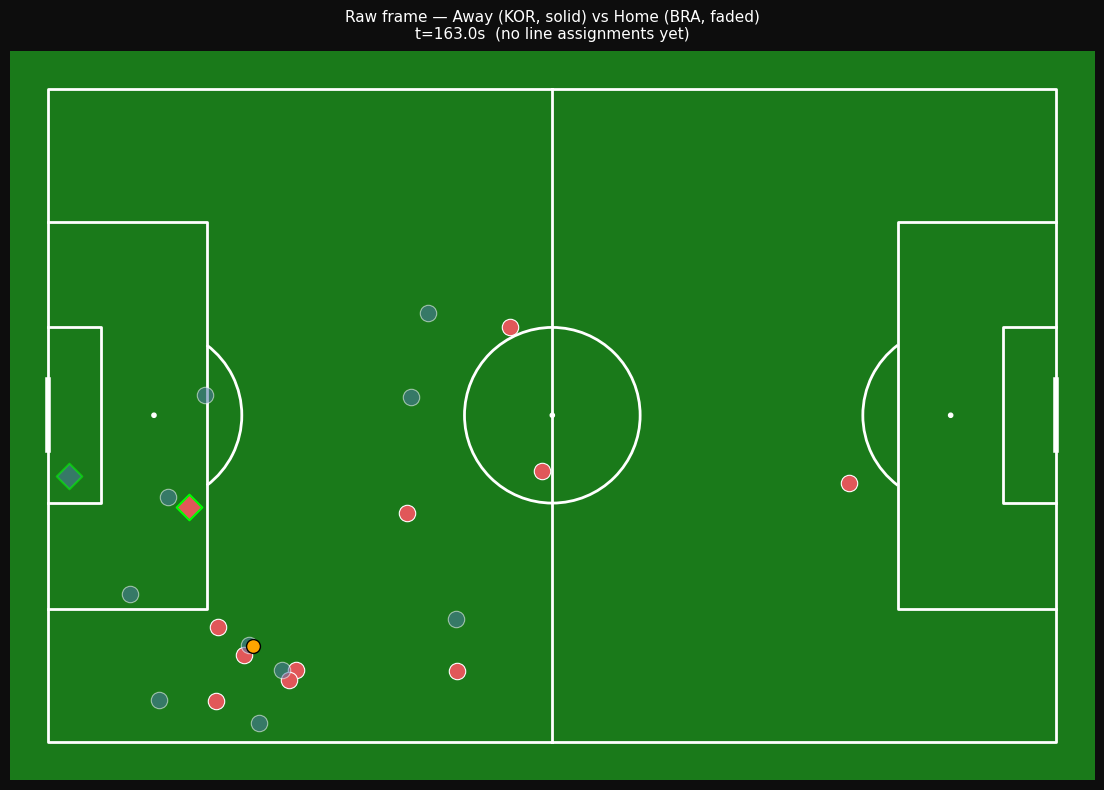

In [4]:
pitch = make_pitch()
fig, ax = pitch.draw(figsize=(12, 8))
fig.patch.set_facecolor('#0d0d0d')

plot_frame(ax, clip.iloc[0], home_team=defending_team, away_team=attacking_team)

ax.set_title(
    f'Raw frame — {defending_team} (KOR, solid) vs {attacking_team} (BRA, faded)\n'
    f't={start_t:.1f}s  (no line assignments yet)',
    color='white', fontsize=11, pad=8
)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'raw_frame.png', dpi=120, bbox_inches='tight')
plt.show()

## Run the detection pipeline

1. `analyze_lines` — Ward clustering assigns each outfield player to a line (0=GK, 1–4=lines)
2. `vote_line_count` — majority vote across all frames to choose K
3. `analyze_lines(..., force_n_lines=K)` — re-cluster with forced K
4. `fix_player_assignments` — temporal smoothing to reduce flickering

In [5]:
first_pass = analyze_lines(clip, defending_team)
k = vote_line_count(first_pass)
lines_df = fix_player_assignments(
    analyze_lines(clip, defending_team, force_n_lines=k),
    defending_team,
)

print(f'Voted line count K = {k}')

# Show player-to-line assignments in the first frame
first_row = lines_df.iloc[0]
assignments: dict[int, list[int]] = {}
n = 1
while True:
    xc = f'{defending_team}_{n}_x'
    if xc not in first_row.index:
        break
    lc = f'{defending_team}_{n}_line'
    import math
    try:
        ln = int(float(first_row[lc]))
        if not math.isnan(float(first_row[xc])):
            assignments.setdefault(ln, []).append(n)
    except (KeyError, ValueError, TypeError):
        pass
    n += 1

for ln_key in sorted(assignments):
    label = 'GK' if ln_key == 0 else f'Line {ln_key}'
    print(f'  {label}: players {assignments[ln_key]}')

Voted line count K = 2
  GK: players [16]
  Line 1: players [2, 3, 6, 9, 10, 11, 12, 13, 14]
  Line 2: players [1]


## Frame with detected unit lines

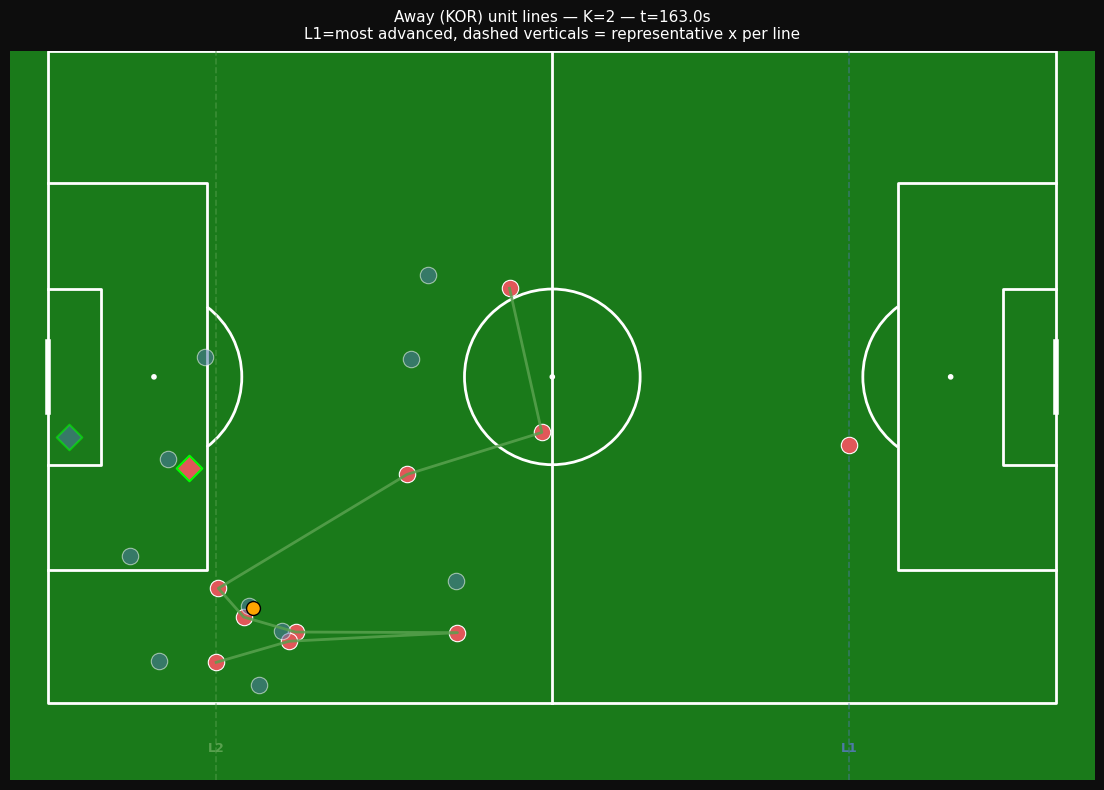

In [6]:
pitch = make_pitch()
fig, ax = pitch.draw(figsize=(12, 8))
fig.patch.set_facecolor('#0d0d0d')
ax.set_ylim(-42, 34)

plot_lines_frame(
    ax, lines_df.iloc[0],
    defending_team=defending_team, attacking_team=attacking_team,
)

ax.set_title(
    f'{defending_team} (KOR) unit lines — K={k} — t={start_t:.1f}s\n'
    'L1=most advanced, dashed verticals = representative x per line',
    color='white', fontsize=11, pad=8
)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'lines_frame.png', dpi=120, bbox_inches='tight')
plt.show()

## Animated clip

Saved to `results/linevis.gif` (gitignored). Shows line assignments evolving across all frames.

In [7]:
# Split merged frames back into per-team frames (animate_lines expects separate DFs)
def_cols = ['Period', 'Time [s]', 'ball_x', 'ball_y'] + \
    [c for c in lines_df.columns if c.startswith(f'{defending_team}_')]
atk_cols = ['Period', 'Time [s]', 'ball_x', 'ball_y'] + \
    [c for c in lines_df.columns if c.startswith(f'{attacking_team}_')]

def_frames = lines_df[def_cols].copy()
atk_frames = lines_df[atk_cols].copy()

anim = animate_lines(
    def_frames, atk_frames,
    defending_team=defending_team,
    attacking_team=attacking_team,
    metadata={'period': period},
    fps=25.0,
    smooth_lines=False,   # already smoothed by fix_player_assignments
)

gif_path = RESULTS_DIR / 'linevis.gif'
anim.save(str(gif_path), writer='pillow', fps=25)
plt.close('all')
print(f'Saved: {gif_path}')

Saved: results\linevis.gif


## Findings

- The algorithm detected **K lines** for the defending team during this event.
- Lines are stable across frames after `fix_player_assignments` smoothing.
- The dashed representative-x vertical shows the positional depth of each line.
- Next: see `pass_labelling/notebook.ipynb` to label whether this pass crossed any line.